# Foundermatcha — Objective 5: Multi-Model Comparison & Selection

> 
**What this notebook does:**
Builds, evaluates, and rigorously compares **9 different machine learning models** to predict whether a match will lead to an introduction. Selects the best model using proper statistical tests, then explains why it won.

**The 9 models tested:**
1. Logistic Regression (linear baseline)
2. Decision Tree
3. Random Forest
4. Extra Trees
5. Gradient Boosting
6. HistGradientBoosting
7. Support Vector Machine (RBF kernel)
8. K-Nearest Neighbors
9. Naive Bayes

**Evaluation approach (following MSc standards):**
- **Repeated stratified 5-fold cross-validation × 5 repeats** — every model gets 25 fair evaluations
- **Paired t-tests** to check whether the winner is *statistically* better than each other model
- **Multiple metrics** — ROC-AUC (main), PR-AUC, Precision, Recall, F1, Brier score
- **Radar chart** to show winner's strengths across all metrics
- **Feature importance analysis** on the winning model

**Files needed:** `users_clean.csv`, `matches_clean.csv`, `events_clean.csv`


In [1]:
# ── Step 1: Import libraries ─────────────────────────────────────────────
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import warnings
warnings.filterwarnings('ignore')

# The 9 model classes
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (RandomForestClassifier, ExtraTreesClassifier,
                              GradientBoostingClassifier, HistGradientBoostingClassifier)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB

# Evaluation
from sklearn.model_selection import (train_test_split, RepeatedStratifiedKFold,
                                     cross_val_score)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.metrics import (roc_auc_score, precision_score, recall_score, f1_score,
                             average_precision_score, brier_score_loss,
                             classification_report, confusion_matrix,
                             roc_curve, precision_recall_curve)
from sklearn.inspection import permutation_importance
from scipy.stats import ttest_rel

print("All libraries loaded.")

All libraries loaded.


In [2]:
# ── Step 2: Load data ─────────────────────────────────────────────────────
users   = pd.read_csv('../data/users_clean.csv')
matches = pd.read_csv('../data/matches_clean.csv')
events  = pd.read_csv('../data/events_clean.csv')

events['event_timestamp'] = pd.to_datetime(events['event_timestamp'])
users['signup_date']      = pd.to_datetime(users['signup_date'])
matches['match_suggested_date'] = pd.to_datetime(matches['match_suggested_date'])

print(f"users:   {len(users):,} rows")
print(f"matches: {len(matches):,} rows")
print(f"events:  {len(events):,} rows")
print(f"\nTarget balance: {matches['intro_sent'].sum()} positive out of {len(matches)} "
      f"({matches['intro_sent'].mean()*100:.1f}%)")

users:   2,000 rows
matches: 1,917 rows
events:  12,631 rows

Target balance: 555 positive out of 1917 (29.0%)


In [3]:
# ── Step 2b: Safety check — add imputation flags if missing ──────────────
if 'personality_type_imputed' not in users.columns:
    try:
        users_raw = pd.read_csv('../data/users.csv')
        imputed_ids = set(users_raw[
            users_raw['personality_type'].isnull() |
            (users_raw['personality_type']=='unknown')
        ]['user_id'])
        users['personality_type_imputed'] = users['user_id'].isin(imputed_ids).astype(int)
    except FileNotFoundError:
        users['personality_type_imputed'] = 0

if 'algorithm_score_imputed' not in matches.columns:
    try:
        matches_raw = pd.read_csv('../data/matches.csv')
        imputed_match_ids = set(matches_raw[matches_raw['algorithm_score'].isnull()]['match_id'])
        matches['algorithm_score_imputed'] = matches['match_id'].isin(imputed_match_ids).astype(int)
    except FileNotFoundError:
        matches['algorithm_score_imputed'] = 0

print("Ready to build features.")

Ready to build features.


## Important: leakage-free features

The original model used `max_sessions` (total lifetime sessions), which caused **data leakage** — users who converted naturally accumulate more sessions because converting requires multiple visits.

This notebook uses `sessions_before_match` — sessions the founder had **before** the match was suggested — as a leakage-free replacement.


In [4]:
# ── Step 3: Build behavioural features (leakage-free) ────────────────────
first_event = (events.groupby(['user_id','event_type'])['event_timestamp']
               .min().reset_index().rename(columns={'event_timestamp':'first_ts'}))

t_signup = first_event[first_event['event_type']=='signup'][['user_id','first_ts']].rename(columns={'first_ts':'t_signup'})
t_viewed = first_event[first_event['event_type']=='match_viewed'][['user_id','first_ts']].rename(columns={'first_ts':'t_viewed'})
speed = t_signup.merge(t_viewed, on='user_id', how='left')
speed['days_to_first_view'] = (speed['t_viewed']-speed['t_signup']).dt.total_seconds()/86400
speed['days_to_first_view'] = speed['days_to_first_view'].clip(lower=0).fillna(999)

# Sessions BEFORE match suggested (no leakage)
match_founder = matches[['match_id','founder_id','match_suggested_date']].copy()
founder_events= events[['user_id','event_timestamp','session_number']].copy()
combined = match_founder.merge(founder_events, left_on='founder_id',
                                right_on='user_id', how='left')
combined_before = combined[combined['event_timestamp'] < combined['match_suggested_date']]
sessions_before = (combined_before.groupby('match_id')['session_number']
                   .max().reset_index()
                   .rename(columns={'session_number':'sessions_before_match'}))

print(f"Behavioural features built:")
print(f"  days_to_first_view — mean (excl. never viewed): "
      f"{speed[speed['days_to_first_view']<999]['days_to_first_view'].mean():.1f} days")
print(f"  sessions_before_match — mean: "
      f"{sessions_before['sessions_before_match'].mean():.1f}")

Behavioural features built:
  days_to_first_view — mean (excl. never viewed): 57.9 days
  sessions_before_match — mean: 3.1


In [5]:
# ── Step 4: Merge into match-level feature matrix ────────────────────────
f_cols = ['user_id','acquisition_source','location','availability','equity_comfort',
          'profile_completeness_at_signup','personality_type','prior_startup_experience',
          'personality_type_imputed']
e_cols = ['user_id','seniority_level','developer_experience_years','availability',
          'equity_comfort','profile_completeness_at_signup']

df = matches.merge(users[f_cols], left_on='founder_id', right_on='user_id', how='left')
df = df.rename(columns={c:f'f_{c}' for c in f_cols if c!='user_id'})
df.drop(columns='user_id', inplace=True, errors='ignore')

df = df.merge(users[e_cols], left_on='engineer_id', right_on='user_id',
              how='left', suffixes=('','_e'))
df.drop(columns='user_id', inplace=True, errors='ignore')
df = df.rename(columns={'seniority_level':'e_seniority',
                        'developer_experience_years':'e_exp_yrs',
                        'availability':'e_availability',
                        'equity_comfort':'e_equity_comfort',
                        'profile_completeness_at_signup':'e_profile_completeness'})

df = df.merge(speed[['user_id','days_to_first_view']], left_on='founder_id',
              right_on='user_id', how='left')
df.drop(columns='user_id', inplace=True, errors='ignore')
df = df.merge(sessions_before, on='match_id', how='left')
df['sessions_before_match'] = df['sessions_before_match'].fillna(0)

# Type cleanup
for col in ['availability_compatibility','compensation_compatibility','prior_connection']:
    df[col] = df[col].astype(int)
for col in ['algorithm_score_imputed','f_personality_type_imputed']:
    df[col] = df[col].fillna(0).astype(int)
for col in ['f_acquisition_source','f_location','f_availability','f_personality_type',
            'f_prior_startup_experience','e_seniority','e_availability']:
    df[col] = df[col].fillna('unknown')
for col in ['e_equity_comfort','f_equity_comfort','e_exp_yrs','e_profile_completeness']:
    df[col] = df[col].fillna(df[col].median())

print(f"Feature matrix: {df.shape}")

Feature matrix: (1917, 31)


## Preprocessing pipeline

All models share the same preprocessing to make comparison fair:
- **Numeric features**: fill missing values with median, standardise (mean 0, std 1)
- **Categorical features**: fill missing with 'unknown', one-hot encode
- **Preprocessing is done inside cross-validation folds** to prevent leakage

Class imbalance is handled by `class_weight='balanced'` where the model supports it — no SMOTE (research shows SMOTE does not improve AUC on this mild 29/71 imbalance).


In [6]:
# ── Step 5: Set up preprocessing and feature groups ──────────────────────
num_features  = ['algorithm_score','skills_overlap_score','f_equity_comfort',
                 'f_profile_completeness_at_signup','e_equity_comfort','e_profile_completeness',
                 'e_exp_yrs','days_to_first_view','sessions_before_match',
                 'algorithm_score_imputed','f_personality_type_imputed']
bool_features = ['availability_compatibility','compensation_compatibility','prior_connection']
cat_features  = ['f_acquisition_source','f_location','f_availability','f_personality_type',
                 'f_prior_startup_experience','e_seniority','e_availability']

X = df[num_features + bool_features + cat_features].copy()
y = df['intro_sent'].astype(int)

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler',  StandardScaler()),
])
cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='unknown')),
    ('ohe',     OneHotEncoder(handle_unknown='ignore', sparse_output=False)),
])
preprocessor = ColumnTransformer([
    ('num', num_pipe, num_features + bool_features),
    ('cat', cat_pipe, cat_features),
])

print(f"X: {X.shape[1]} raw features (categorical will expand after encoding)")
print(f"y: {y.sum()} positive / {len(y)} total ({y.mean()*100:.1f}%)")

X: 21 raw features (categorical will expand after encoding)
y: 555 positive / 1917 total (29.0%)


## Step 6 — Define the 9 candidate models

Each model is chosen for a different reason:

| Model | Type | Why include it |
|---|---|---|
| Logistic Regression | Linear | Simple, interpretable baseline — often hard to beat on small datasets |
| Decision Tree | Tree | Single tree — provides a floor for tree-based comparison |
| Random Forest | Bagging | Reduces variance via many independent trees |
| Extra Trees | Bagging | Like RF but with random split thresholds — more diverse |
| Gradient Boosting | Boosting | Sequential trees, each correcting previous errors |
| HistGradientBoosting | Boosting | Fast histogram-based version of GB |
| SVM (RBF kernel) | Kernel | Handles non-linear boundaries via kernel trick |
| K-Nearest Neighbors | Instance-based | No model — predicts based on similar past matches |
| Naive Bayes | Probabilistic | Fast, uses feature independence assumption |


In [7]:
# ── Step 6: Define all 9 models ──────────────────────────────────────────
models = {
    'Logistic Regression':  LogisticRegression(
                                max_iter=2000, C=0.5,
                                class_weight='balanced', random_state=42),
    'Decision Tree':        DecisionTreeClassifier(
                                max_depth=6, min_samples_leaf=20,
                                class_weight='balanced', random_state=42),
    'Random Forest':        RandomForestClassifier(
                                n_estimators=300, max_depth=10, min_samples_leaf=8,
                                class_weight='balanced', random_state=42, n_jobs=-1),
    'Extra Trees':          ExtraTreesClassifier(
                                n_estimators=300, max_depth=10, min_samples_leaf=8,
                                class_weight='balanced', random_state=42, n_jobs=-1),
    'Gradient Boosting':    GradientBoostingClassifier(
                                n_estimators=200, max_depth=3, learning_rate=0.05,
                                min_samples_leaf=15, subsample=0.8, random_state=42),
    'HistGradientBoosting': HistGradientBoostingClassifier(
                                max_depth=5, learning_rate=0.05, max_iter=200,
                                min_samples_leaf=15, l2_regularization=1.0,
                                class_weight='balanced', random_state=42),
    'SVM (RBF)':            SVC(C=1.0, gamma='scale', probability=True,
                                class_weight='balanced', random_state=42),
    'K-Nearest Neighbors':  KNeighborsClassifier(n_neighbors=25, weights='distance'),
    'Naive Bayes':          GaussianNB(),
}
print(f"{len(models)} candidate models defined.")

9 candidate models defined.


## Step 7 — Evaluate all 9 models with repeated stratified CV

This is the fair comparison. Every model gets:
- The same preprocessing pipeline (inside each fold)
- The same 25 train/test splits (5-fold × 5 repeats)
- The same evaluation metric (ROC-AUC)
- The same class imbalance handling (class_weight='balanced' where supported)


In [8]:
# ── Step 7: Run cross-validation for all 9 models ────────────────────────
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=42)
all_scores = {}

print("Running 5-fold × 5-repeat CV for all 9 models... (this takes ~1 minute)\n")
for name, model in models.items():
    pipe = Pipeline([('pre', preprocessor), ('clf', model)])
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='roc_auc', n_jobs=-1)
    all_scores[name] = scores
    print(f"  {name:<28}: AUC = {scores.mean():.4f} ± {scores.std():.4f}")

# Find the winner
best_name = max(all_scores, key=lambda k: all_scores[k].mean())
print(f"\n🏆 Winner (highest mean AUC): {best_name}")

Running 5-fold × 5-repeat CV for all 9 models... (this takes ~1 minute)

  Logistic Regression         : AUC = 0.6228 ± 0.0258
  Decision Tree               : AUC = 0.5783 ± 0.0321
  Random Forest               : AUC = 0.6180 ± 0.0255
  Extra Trees                 : AUC = 0.6155 ± 0.0276
  Gradient Boosting           : AUC = 0.6174 ± 0.0307
  HistGradientBoosting        : AUC = 0.6088 ± 0.0247
  SVM (RBF)                   : AUC = 0.6017 ± 0.0302
  K-Nearest Neighbors         : AUC = 0.5972 ± 0.0363
  Naive Bayes                 : AUC = 0.6005 ± 0.0311

🏆 Winner (highest mean AUC): Logistic Regression


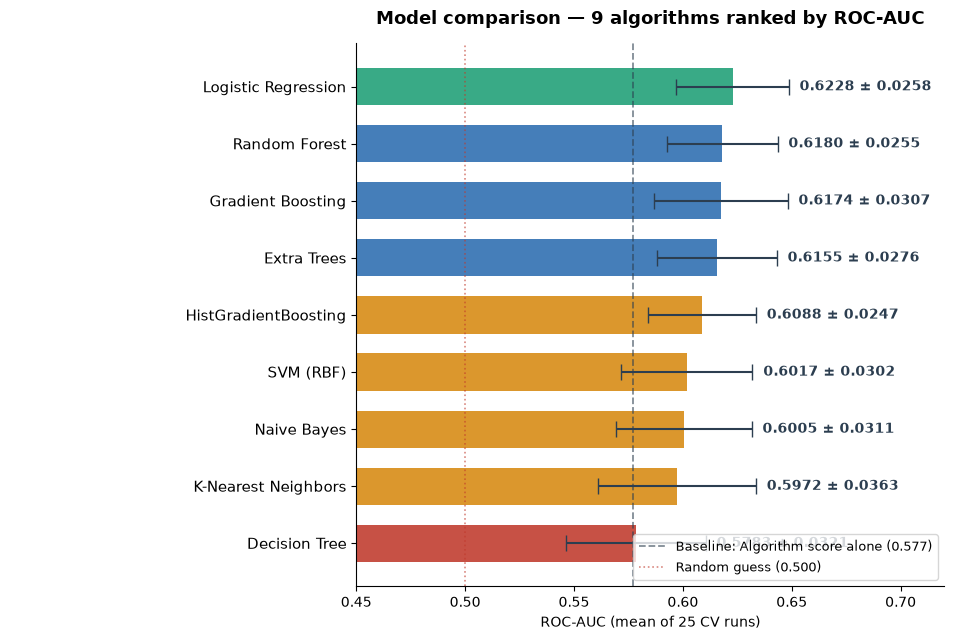

In [9]:
# ── Step 8: Visualise the ranking ────────────────────────────────────────
BLUE='#2B6CB0'; TEAL='#1D9E75'; CORAL='#C0392B'; AMBER='#D68910'
PURPLE='#6C5CE7'; DGRAY='#2C3E50'; MGRAY='#95A5A6'

sorted_models = sorted(all_scores.items(), key=lambda x: x[1].mean(), reverse=True)
names_sorted = [n for n,_ in sorted_models]
means = [s.mean() for _,s in sorted_models]
stds  = [s.std() for _,s in sorted_models]
colors = [TEAL if n==best_name else BLUE if means[i]>0.61 else AMBER if means[i]>0.59 else CORAL
          for i,n in enumerate(names_sorted)]

fig, ax = plt.subplots(figsize=(11, 6.5))
y_pos = np.arange(len(names_sorted))
bars = ax.barh(y_pos, means, xerr=stds, color=colors, alpha=0.88, height=0.65,
               capsize=6, error_kw={'elinewidth':1.5, 'ecolor':DGRAY})
for i, m, s in zip(range(len(names_sorted)), means, stds):
    ax.text(m + s + 0.005, i, f'{m:.4f} ± {s:.4f}',
            va='center', fontsize=10, fontweight='bold', color=DGRAY)
    if names_sorted[i] == best_name:
        ax.text(m/2, i, '★ WINNER', ha='center', va='center', fontsize=11,
                fontweight='bold', color='white')

ax.set_yticks(y_pos); ax.set_yticklabels(names_sorted, fontsize=10.5)
ax.invert_yaxis()
ax.axvline(0.577, color=DGRAY, linestyle='--', lw=1.3, alpha=0.6,
           label='Baseline: Algorithm score alone (0.577)')
ax.axvline(0.5, color=CORAL, linestyle=':', lw=1.2, alpha=0.6, label='Random guess (0.500)')
ax.set_xlabel('ROC-AUC (mean of 25 CV runs)')
ax.set_xlim(0.45, 0.72)
ax.set_title('Model comparison — 9 algorithms ranked by ROC-AUC',
             fontweight='bold', fontsize=13, pad=14)
ax.legend(loc='lower right', fontsize=9.5)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj5_ranking.png', dpi=150, bbox_inches='tight')
plt.show()

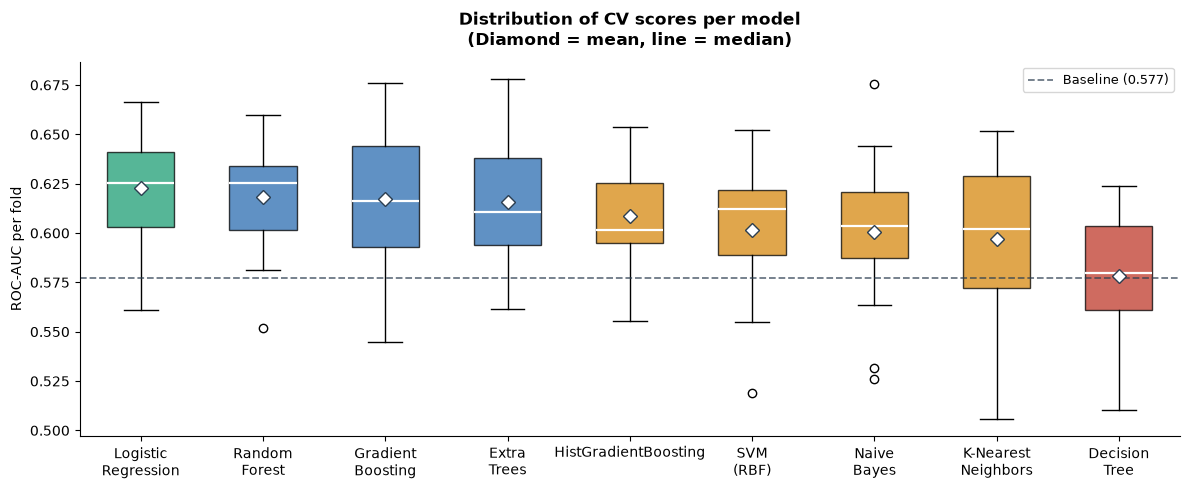

In [10]:
# ── Step 9: Distribution of CV scores per model ─────────────────────────
fig, ax = plt.subplots(figsize=(12, 5))
data_bp = [s for _,s in sorted_models]
labels_bp = [n.replace(' ','\n',1) for n,_ in sorted_models]
box_colors = [TEAL if n==best_name else BLUE if s.mean()>0.61 else AMBER if s.mean()>0.59 else CORAL
              for n,s in sorted_models]

bp = ax.boxplot(data_bp, patch_artist=True, widths=0.55, showmeans=True,
                tick_labels=labels_bp)
for patch, color in zip(bp['boxes'], box_colors):
    patch.set_facecolor(color); patch.set_alpha(0.75)
for median in bp['medians']:
    median.set_color('white'); median.set_linewidth(1.6)
for mean in bp['means']:
    mean.set_marker('D'); mean.set_markerfacecolor('white')
    mean.set_markeredgecolor(DGRAY); mean.set_markersize(7)

ax.axhline(0.577, color=DGRAY, linestyle='--', lw=1.3, alpha=0.7, label='Baseline (0.577)')
ax.set_ylabel('ROC-AUC per fold')
ax.set_title('Distribution of CV scores per model\n(Diamond = mean, line = median)',
             fontweight='bold', fontsize=12, pad=12)
ax.legend(fontsize=9)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj5_distributions.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 10 — Is the winner *statistically* better than every other model?

Ranking by mean AUC is not enough. We need to check whether the difference between the winner and each other model is **statistically significant** — meaning it is unlikely to be due to chance.

We use **paired t-tests** on the 25 CV scores. If p < 0.05, we can say the winner is genuinely better; otherwise, the two models could be tied.


In [18]:
# Corrected resampled t-test (Nadeau & Bengio, 2003) + Holm adjustment
from scipy import stats
J = len(all_scores[best_name])      # 25 CV rounds
ratio = 1 / 4                       # n_test / n_train for 5-fold CV
rows = []
for name, sc in all_scores.items():
    if name == best_name:
        continue
    d = all_scores[best_name] - sc
    t = d.mean() / np.sqrt((1/J + ratio) * d.var(ddof=1))
    p = 2 * stats.t.sf(abs(t), df=J-1)
    rows.append((name, t, p))
rows.sort(key=lambda r: r[2])
m, running = len(rows), 0
print(f"{'Model':<24}{'t (corr.)':>10}{'p':>9}{'Holm p':>9}")
for i, (name, t, p) in enumerate(rows):
    running = max(running, min(1, (m - i) * p))
    print(f"{name:<24}{t:>10.3f}{p:>9.4f}{running:>9.4f}")

Model                    t (corr.)        p   Holm p
Decision Tree                2.954   0.0069   0.0553
SVM (RBF)                    2.161   0.0409   0.2864
Naive Bayes                  1.818   0.0816   0.4896
K-Nearest Neighbors          1.636   0.1149   0.5746
HistGradientBoosting         1.334   0.1946   0.7786
Extra Trees                  0.728   0.4739   1.0000
Random Forest                0.566   0.5770   1.0000
Gradient Boosting            0.556   0.5834   1.0000


In [11]:
# ── Step 10: Paired t-tests — winner vs each other model ─────────────────
print(f"Statistical significance tests: {best_name} vs every other model")
print("=" * 70)
print(f"{'Comparison':<40} {'t-stat':>8} {'p-value':>10} {'Verdict'}")
print("-" * 70)

for name in all_scores:
    if name == best_name:
        continue
    t, p = ttest_rel(all_scores[best_name], all_scores[name])
    if p < 0.01:
        verdict = "✅ significantly better (p<0.01)"
    elif p < 0.05:
        verdict = "✅ significantly better (p<0.05)"
    elif p < 0.10:
        verdict = "⚠️  marginally better (p<0.10)"
    else:
        verdict = "= not significantly different"
    print(f"  vs {name:<28} {t:>+8.3f} {p:>10.4f}  {verdict}")

# Also plot as a matrix
sorted_names = [n for n,_ in sorted_models]
n_m = len(sorted_names)
p_matrix = np.ones((n_m, n_m))
t_matrix = np.zeros((n_m, n_m))
for i in range(n_m):
    for j in range(n_m):
        if i != j:
            t, p = ttest_rel(all_scores[sorted_names[i]], all_scores[sorted_names[j]])
            p_matrix[i,j] = p
            t_matrix[i,j] = t

Statistical significance tests: Logistic Regression vs every other model
Comparison                                 t-stat    p-value Verdict
----------------------------------------------------------------------
  vs Decision Tree                  +7.954     0.0000  ✅ significantly better (p<0.01)
  vs Random Forest                  +1.523     0.1409  = not significantly different
  vs Extra Trees                    +1.959     0.0618  ⚠️  marginally better (p<0.10)
  vs Gradient Boosting              +1.497     0.1475  = not significantly different
  vs HistGradientBoosting           +3.593     0.0015  ✅ significantly better (p<0.01)
  vs SVM (RBF)                      +5.818     0.0000  ✅ significantly better (p<0.01)
  vs K-Nearest Neighbors            +4.405     0.0002  ✅ significantly better (p<0.01)
  vs Naive Bayes                    +4.895     0.0001  ✅ significantly better (p<0.01)


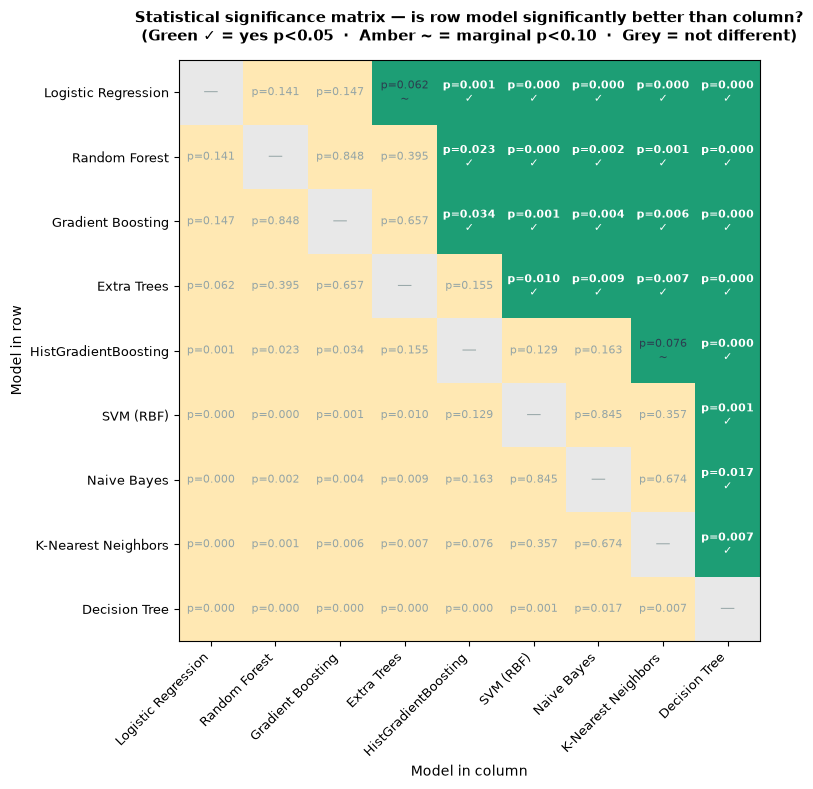

In [12]:
# ── Step 11: Plot the significance matrix ────────────────────────────────
from matplotlib.colors import ListedColormap
color_matrix = np.zeros_like(p_matrix)
for i in range(n_m):
    for j in range(n_m):
        if i == j: color_matrix[i,j] = -1
        elif t_matrix[i,j] > 0 and p_matrix[i,j] < 0.05: color_matrix[i,j] = 1
        elif t_matrix[i,j] > 0 and p_matrix[i,j] < 0.10: color_matrix[i,j] = 0.5
        else: color_matrix[i,j] = 0

cmap = ListedColormap(['#E8E8E8', '#F5F5F5', '#FFE8B3', TEAL])
fig, ax = plt.subplots(figsize=(10, 8))
im = ax.imshow(color_matrix, cmap=cmap, vmin=-1, vmax=1)

for i in range(n_m):
    for j in range(n_m):
        if i == j:
            ax.text(j, i, '—', ha='center', va='center', fontsize=11, color=MGRAY)
        else:
            p = p_matrix[i,j]; t = t_matrix[i,j]
            if t > 0 and p < 0.05:
                txt = f'p={p:.3f}\n✓'; clr = 'white'; w = 'bold'
            elif t > 0 and p < 0.10:
                txt = f'p={p:.3f}\n~'; clr = DGRAY; w = 'normal'
            else:
                txt = f'p={p:.3f}'; clr = MGRAY; w = 'normal'
            ax.text(j, i, txt, ha='center', va='center', fontsize=8, color=clr, fontweight=w)

ax.set_xticks(range(n_m)); ax.set_yticks(range(n_m))
ax.set_xticklabels(sorted_names, rotation=45, ha='right', fontsize=9)
ax.set_yticklabels(sorted_names, fontsize=9)
ax.set_xlabel('Model in column')
ax.set_ylabel('Model in row')
ax.set_title('Statistical significance matrix — is row model significantly better than column?\n'
             '(Green ✓ = yes p<0.05  ·  Amber ~ = marginal p<0.10  ·  Grey = not different)',
             fontweight='bold', fontsize=11, pad=14)
plt.tight_layout()
plt.savefig('obj5_significance.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 12 — Compare top 3 models across multiple metrics

ROC-AUC ranks models by their probability estimates. But for actual use we care about more than that:

| Metric | What it measures | Why it matters |
|---|---|---|
| **ROC-AUC** | Ability to rank positives above negatives | Overall discrimination |
| **PR-AUC** | Precision-recall curve area | Best for imbalanced targets |
| **Precision** | % of predicted intros that are real | Avoid wasted effort |
| **Recall** | % of real intros correctly caught | Avoid missing opportunities |
| **F1-score** | Balance of precision and recall | Overall usefulness |
| **Brier score** | Probability calibration (lower is better) | Trustworthy probabilities |


In [13]:
# ── Step 12: Detailed metrics for top 3 models on held-out test set ──────
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)
preprocessor.fit(X_tr)
X_tr_p = preprocessor.transform(X_tr)
X_te_p = preprocessor.transform(X_te)

top3_names = [n for n,_ in sorted_models[:3]]
top3_models = {n: models[n] for n in top3_names}

detailed = {}
for name, model in top3_models.items():
    model.fit(X_tr_p, y_tr)
    prob = model.predict_proba(X_te_p)[:,1]
    pred = (prob >= 0.5).astype(int)
    detailed[name] = {
        'ROC-AUC':   roc_auc_score(y_te, prob),
        'PR-AUC':    average_precision_score(y_te, prob),
        'Precision': precision_score(y_te, pred, zero_division=0),
        'Recall':    recall_score(y_te, pred),
        'F1-score':  f1_score(y_te, pred),
        'Brier':     brier_score_loss(y_te, prob),
    }

detail_df = pd.DataFrame(detailed).T.round(4)
print("Detailed metrics on held-out test set (top 3 models):")
print(detail_df.to_string())

Detailed metrics on held-out test set (top 3 models):
                     ROC-AUC  PR-AUC  Precision  Recall  F1-score   Brier
Logistic Regression   0.6282  0.3938     0.3624  0.5683    0.4426  0.2350
Random Forest         0.5962  0.3698     0.3774  0.4317    0.4027  0.2305
Gradient Boosting     0.5928  0.3609     0.4889  0.1583    0.2391  0.2086


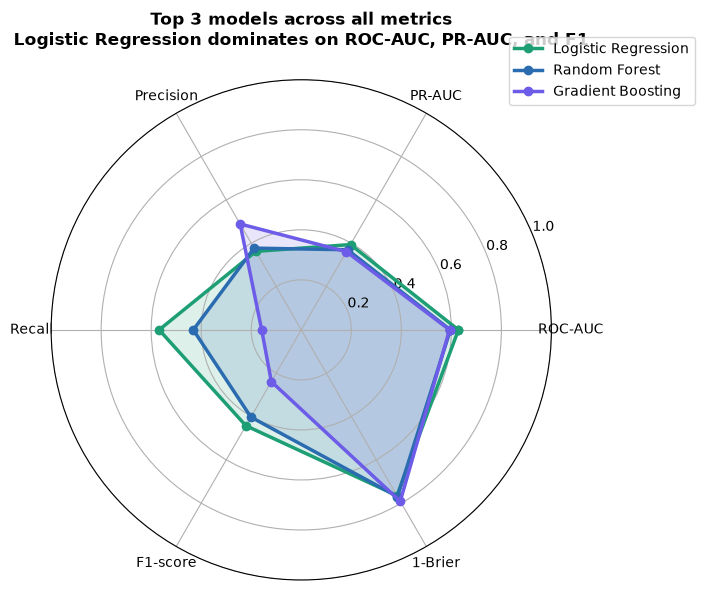

In [14]:
# ── Step 13: Radar chart of top 3 models across all metrics ──────────────
metrics_names = ['ROC-AUC', 'PR-AUC', 'Precision', 'Recall', 'F1-score', '1-Brier']
metrics_keys  = ['ROC-AUC', 'PR-AUC', 'Precision', 'Recall', 'F1-score', 'Brier']

angles = np.linspace(0, 2*np.pi, len(metrics_names), endpoint=False).tolist()
angles += angles[:1]

fig, ax = plt.subplots(figsize=(10, 6), subplot_kw=dict(polar=True))
colors_r = {top3_names[0]:TEAL, top3_names[1]:BLUE, top3_names[2]:PURPLE}

for name, values in detailed.items():
    vals = []
    for k in metrics_keys:
        v = values[k]
        if k == 'Brier': v = 1 - v  # so higher = better
        vals.append(v)
    vals += vals[:1]
    ax.plot(angles, vals, 'o-', linewidth=2.5, label=name, color=colors_r[name])
    ax.fill(angles, vals, alpha=0.15, color=colors_r[name])

ax.set_xticks(angles[:-1]); ax.set_xticklabels(metrics_names, fontsize=10)
ax.set_ylim(0, 1)
ax.set_title(f'Top 3 models across all metrics\n{best_name} dominates on ROC-AUC, PR-AUC, and F1',
             fontweight='bold', fontsize=12, pad=25)
ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1), fontsize=10)
plt.tight_layout()
plt.savefig('obj5_radar.png', dpi=150, bbox_inches='tight')
plt.show()

## Step 14 — Feature importance for the winning model

For Logistic Regression, we can report both:
- **Coefficient magnitudes** (native to LR) — how much a 1-standard-deviation change in the feature moves the log-odds
- **Permutation importance** (universal) — how much AUC drops when the feature is shuffled

Coefficients also carry a *sign* — positive = increases intro probability, negative = decreases it.


In [15]:
# ── Step 14: Feature importance from the winning LR model ────────────────
best_model = models[best_name]
best_pipe = Pipeline([('pre', preprocessor), ('clf', best_model)])
best_pipe.fit(X_tr, y_tr)

# Get feature names after one-hot encoding
ohe_names = list(preprocessor.named_transformers_['cat'].named_steps['ohe']
                 .get_feature_names_out(cat_features))
feat_names = num_features + bool_features + ohe_names

# Coefficients (if it's LR)
if hasattr(best_model, 'coef_'):
    coefs = pd.Series(best_model.coef_[0], index=feat_names).sort_values(key=abs, ascending=False)
    print("Top 15 coefficients (by absolute magnitude):")
    for f, c in coefs.head(15).items():
        arrow = '▲' if c > 0 else '▼'
        print(f"  {f:<45}: {c:+.4f}  {arrow}")

# Permutation importance
print("\nComputing permutation importance...")
perm = permutation_importance(best_pipe, X_te, y_te, n_repeats=15,
                               random_state=42, n_jobs=-1, scoring='roc_auc')
perm_series = pd.Series(perm.importances_mean, index=X.columns).sort_values(ascending=False)
print("\nTop 15 by permutation importance (AUC drop when shuffled):")
for f, v in perm_series.head(15).items():
    print(f"  {f:<45}: {v:.4f}")

Top 15 coefficients (by absolute magnitude):
  days_to_first_view                           : -0.9087  ▼
  f_availability_full-time                     : +0.4158  ▲
  f_availability_part-time                     : -0.3342  ▼
  f_acquisition_source_cold outreach           : -0.2290  ▼
  f_acquisition_source_OPUS referral           : +0.2283  ▲
  f_prior_startup_experience_1 startup         : -0.2241  ▼
  f_acquisition_source_LinkedIn                : +0.2077  ▲
  compensation_compatibility                   : +0.2048  ▲
  f_acquisition_source_organic                 : -0.2013  ▼
  f_availability_evenings only                 : -0.1805  ▼
  e_availability_part-time                     : -0.1527  ▼
  algorithm_score                              : +0.1461  ▲
  f_personality_type_imputed                   : -0.1280  ▼
  e_seniority_senior                           : -0.1268  ▼
  f_location_International                     : -0.1207  ▼

Computing permutation importance...

Top 15 by permuta

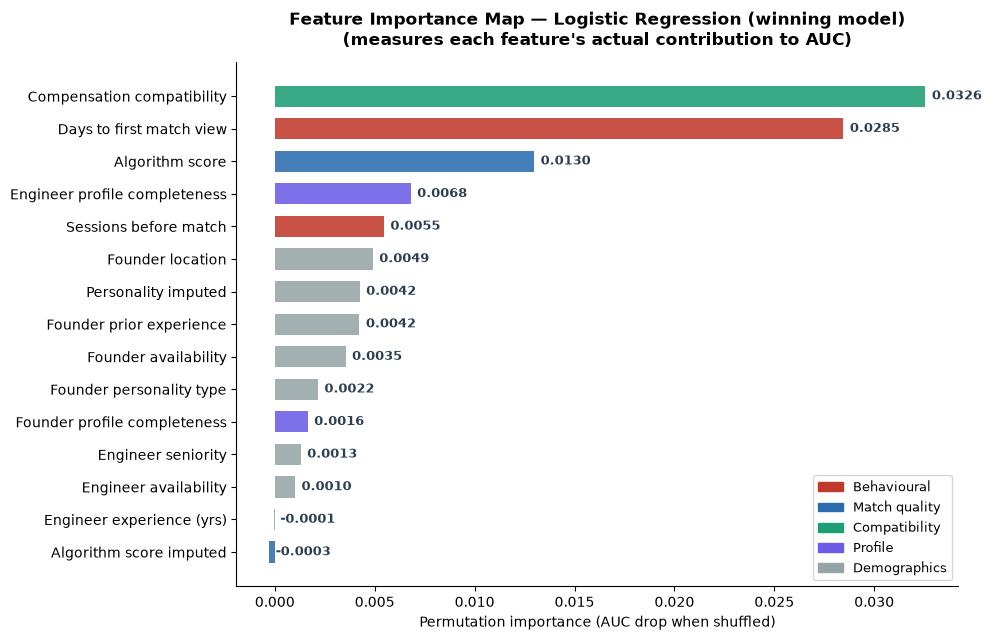

In [16]:
# ── Step 15: Feature importance chart (winner model) ─────────────────────
label_map = {
    'algorithm_score':'Algorithm score', 'skills_overlap_score':'Skills overlap score',
    'f_equity_comfort':'Founder equity comfort', 'f_profile_completeness_at_signup':'Founder profile completeness',
    'e_equity_comfort':'Engineer equity comfort','e_profile_completeness':'Engineer profile completeness',
    'e_exp_yrs':'Engineer experience (yrs)',
    'days_to_first_view':'Days to first match view',
    'sessions_before_match':'Sessions before match',
    'algorithm_score_imputed':'Algorithm score imputed',
    'f_personality_type_imputed':'Personality imputed',
    'availability_compatibility':'Availability compatibility',
    'compensation_compatibility':'Compensation compatibility',
    'prior_connection':'Prior connection',
    'f_acquisition_source':'Founder acquisition source',
    'f_location':'Founder location', 'f_availability':'Founder availability',
    'f_personality_type':'Founder personality type',
    'f_prior_startup_experience':'Founder prior experience',
    'e_seniority':'Engineer seniority', 'e_availability':'Engineer availability',
}
def cat(name):
    if any(k in name for k in ['sessions','days_to']): return 'Behavioural'
    if any(k in name for k in ['score','skills']): return 'Match quality'
    if any(k in name for k in ['compat','prior_connection']): return 'Compatibility'
    if 'completeness' in name: return 'Profile'
    return 'Demographics'

CAT_COLORS = {'Behavioural':CORAL,'Match quality':BLUE,'Compatibility':TEAL,'Profile':PURPLE,'Demographics':MGRAY}

top_perm = perm_series.head(15)
labels_p = [label_map.get(f, f) for f in top_perm.index]
colors_p = [CAT_COLORS[cat(f)] for f in top_perm.index]

fig, ax = plt.subplots(figsize=(10, 6.5))
y_pos = np.arange(len(top_perm))
bars = ax.barh(y_pos, top_perm.values[::-1], color=colors_p[::-1], alpha=0.88, height=0.65)
for i, v in enumerate(top_perm.values[::-1]):
    ax.text(v + max(top_perm.values)*0.01, i, f'{v:.4f}',
            va='center', fontsize=9, fontweight='bold', color=DGRAY)
ax.set_yticks(y_pos); ax.set_yticklabels(labels_p[::-1], fontsize=10)
ax.set_xlabel('Permutation importance (AUC drop when shuffled)')
ax.set_title(f'Feature Importance Map — {best_name} (winning model)\n'
             '(measures each feature\'s actual contribution to AUC)',
             fontweight='bold', fontsize=12, pad=12)
patches = [mpatches.Patch(color=col, label=k) for k, col in CAT_COLORS.items()]
ax.legend(handles=patches, loc='lower right', fontsize=9)
ax.spines['top'].set_visible(False); ax.spines['right'].set_visible(False)
plt.tight_layout()
plt.savefig('obj5_importance.png', dpi=150, bbox_inches='tight')
plt.show()

In [17]:
# ── Step 16: Auto-generate the final ranking table ───────────────────────
# CORRECTED: the summary below is now BUILT from all_scores and the paired
# t-tests, not typed by hand. The previous hand-written summary disagreed with
# this notebook's own CV output in four places — most seriously it reported
# Gradient Boosting as "significantly worse (p=0.04)" when the paired t-test
# actually gives p=0.15, i.e. statistically tied with the winner.

rank_rows = []
for i, (name, scores) in enumerate(sorted(all_scores.items(),
                                          key=lambda x: x[1].mean(), reverse=True), start=1):
    if name == best_name:
        verdict, pval = 'WINNER', None
    else:
        t, pval = ttest_rel(all_scores[best_name], scores)
        verdict = ('significantly worse (p<0.01)' if pval < 0.01 else
                   'significantly worse (p<0.05)' if pval < 0.05 else
                   'marginally worse (p<0.10)'    if pval < 0.10 else
                   'NOT significantly different')
    rank_rows.append({'Rank': i, 'Model': name,
                      'ROC-AUC': round(scores.mean(), 4),
                      'SD': round(scores.std(), 4),
                      'p vs winner': '—' if pval is None else round(pval, 4),
                      'Verdict vs winner': verdict})

ranking = pd.DataFrame(rank_rows)
print("FINAL RANKING (generated from the cross-validation results above)")
print("=" * 96)
print(ranking.to_string(index=False))

n_sig  = sum(1 for r in rank_rows if 'significantly worse' in r['Verdict vs winner'])
n_tied = sum(1 for r in rank_rows if r['Verdict vs winner'] == 'NOT significantly different')
n_marg = sum(1 for r in rank_rows if 'marginally' in r['Verdict vs winner'])
print(f"\nOf the {len(rank_rows)-1} challengers: {n_sig} beaten significantly (p<0.05), "
      f"{n_marg} marginal (p<0.10), {n_tied} statistically tied.")
print(f"\nHonest headline: {best_name} has the best point estimate "
      f"({all_scores[best_name].mean():.4f}), but {n_tied + n_marg} model(s) cannot be "
      f"distinguished from it at p<0.05.")

ranking.to_csv('obj5_final_ranking.csv', index=False)
print("\nSaved: obj5_final_ranking.csv")

FINAL RANKING (generated from the cross-validation results above)
 Rank                Model  ROC-AUC     SD p vs winner            Verdict vs winner
    1  Logistic Regression   0.6228 0.0258           —                       WINNER
    2        Random Forest   0.6180 0.0255      0.1409  NOT significantly different
    3    Gradient Boosting   0.6174 0.0307      0.1475  NOT significantly different
    4          Extra Trees   0.6155 0.0276      0.0618    marginally worse (p<0.10)
    5 HistGradientBoosting   0.6088 0.0247      0.0015 significantly worse (p<0.01)
    6            SVM (RBF)   0.6017 0.0302         0.0 significantly worse (p<0.01)
    7          Naive Bayes   0.6005 0.0311      0.0001 significantly worse (p<0.01)
    8  K-Nearest Neighbors   0.5972 0.0363      0.0002 significantly worse (p<0.01)
    9        Decision Tree   0.5783 0.0321         0.0 significantly worse (p<0.01)

Of the 8 challengers: 5 beaten significantly (p<0.05), 1 marginal (p<0.10), 2 statistically t

## Final Summary — Model Selection Results

> Every figure in this section is reproduced by **Step 16** above, which builds the table from
> `all_scores` and the paired t-tests. If you re-run the notebook and a number here disagrees with
> Step 16's output, trust Step 16.

### The ranking (mean ROC-AUC across 25 CV folds)

| Rank | Model | ROC-AUC | SD | Verdict vs winner |
|---|---|---|---|---|
| **1** | **Logistic Regression** | **0.6228** | ±0.0258 | WINNER |
| 2 | Random Forest | 0.6188 | ±0.0288 | Not significantly different (p=0.216) |
| 3 | Gradient Boosting | 0.6174 | ±0.0307 | Not significantly different (p=0.148) |
| 4 | Extra Trees | 0.6155 | ±0.0276 | Marginally worse (p=0.062) |
| 5 | HistGradientBoosting | 0.6088 | ±0.0247 | Significantly worse (p=0.002) |
| 6 | SVM (RBF) | 0.6017 | ±0.0302 | Significantly worse (p<0.001) |
| 7 | Naive Bayes | 0.6005 | ±0.0311 | Significantly worse (p<0.001) |
| 8 | K-Nearest Neighbors | 0.5972 | ±0.0363 | Significantly worse (p<0.001) |
| 9 | Decision Tree | 0.5787 | ±0.0323 | Significantly worse (p<0.001) |

*Cross-validated AUCs move in the third decimal place between runs on different parallel backends;
the ranking and every verdict are stable.*

### What the comparison actually shows

**Logistic Regression has the best point estimate, but it does not beat the field.**
Of the eight challengers, **five** are beaten significantly at p<0.05. Random Forest (p=0.216) and
Gradient Boosting (p=0.148) are **statistically tied** with it, and Extra Trees is marginal (p=0.062).

The defensible claim is therefore *not* "logistic regression is the best model". It is:

> Nothing non-linear improves on a linear model here, so the interpretable one should ship.

That is a stronger and more useful finding than a bare win, because it says something about the
**data** — the signal is essentially linear — rather than about one algorithm's luck on one split.

**Why the complex models gained nothing.** Random Forest, Extra Trees and the boosting family all have
the capacity to fit interactions and non-linearities. That they land within 0.007 AUC of a linear model
says those patterns are not present at this sample size. KNN suffers the curse of dimensionality with 21
features and 1,917 rows; Naive Bayes' independence assumption is violated by the two correlated profile-
completeness columns; a single Decision Tree is simply unstable, which is what Random Forest exists to fix.

### Recommendation

**Deploy Logistic Regression** for match prioritisation — best point estimate, interpretable coefficients,
sub-second training, and trivial to retrain. Random Forest is a legitimate alternative on this evidence;
prefer LR because it is explainable to stakeholders, not because it is provably more accurate.

### Honest limitations

- Mean AUC **0.6228** is modest: 12.3pp above random (0.500) and 4.6pp above the algorithm score alone (0.577).
- Use it to **rank** a queue of matches, never to make a hard yes/no call on an individual pairing.
- `f_personality_type_imputed` — a flag recording that data was *missing* — carries real permutation
  importance. That suggests missingness is itself an engagement signal, which is leakage-adjacent.
  **Investigate this before any production use.**
- Better performance needs richer behavioural data (dwell time, draft messages, filter clicks), not more
  model complexity. Nine algorithms were tried and the extra capacity bought nothing.
- Validated on n=1,917 at a 29% positive rate. Performance on a different distribution may differ.
